## 1. EDA: первичный анализ маленького датасета

В этом разделе мы загружаем student_data.csv, смотрим структуру данных, пропуски, описательные статистики, корреляции и распределение целевой переменной G3.

### Импорт базовых библиотек

Здесь подключаем Path для удобной работы с путями и pandas для чтения и анализа таблиц.

In [225]:
from pathlib import Path

import pandas as pd

### Загрузка данных

Читаем маленький CSV-файл из data/raw и выводим первые строки, чтобы проверить, что данные загрузились корректно.

In [226]:
DATA_PATH = Path("../data/raw/student_data.csv")
df = pd.read_csv(DATA_PATH)
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


### Размер датасета

Смотрим количество строк и столбцов через df.shape.

In [227]:
df.shape

(395, 33)

### Типы данных и непустые значения

df.info() показывает тип каждого столбца и помогает быстро увидеть, есть ли пропуски.

In [228]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

### Проверка пропусков

Считаем пропущенные значения по каждому столбцу и сортируем столбцы по убыванию количества пропусков.

In [229]:
df.isna().sum().sort_values(ascending=False)

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

### Описательные статистики

df.describe() помогает понять диапазоны, средние значения и возможные выбросы в числовых признаках.

In [230]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


### One-hot encoding для EDA

Преобразуем категориальные признаки в числовые 0/1-столбцы, чтобы их можно было использовать в простых моделях и анализе.

In [231]:
df_encoding = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoding.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,1,0,1,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,1,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,1,0,1,1,0,0


### Импорт библиотек для графиков

Подключаем seaborn и matplotlib для визуализаций.

In [232]:
import seaborn as sns
import matplotlib.pyplot as plt

### Корреляционная матрица Спирмена

Строим матрицу корреляций для числовых признаков. Метод Спирмена хорошо подходит для порядковых признаков.

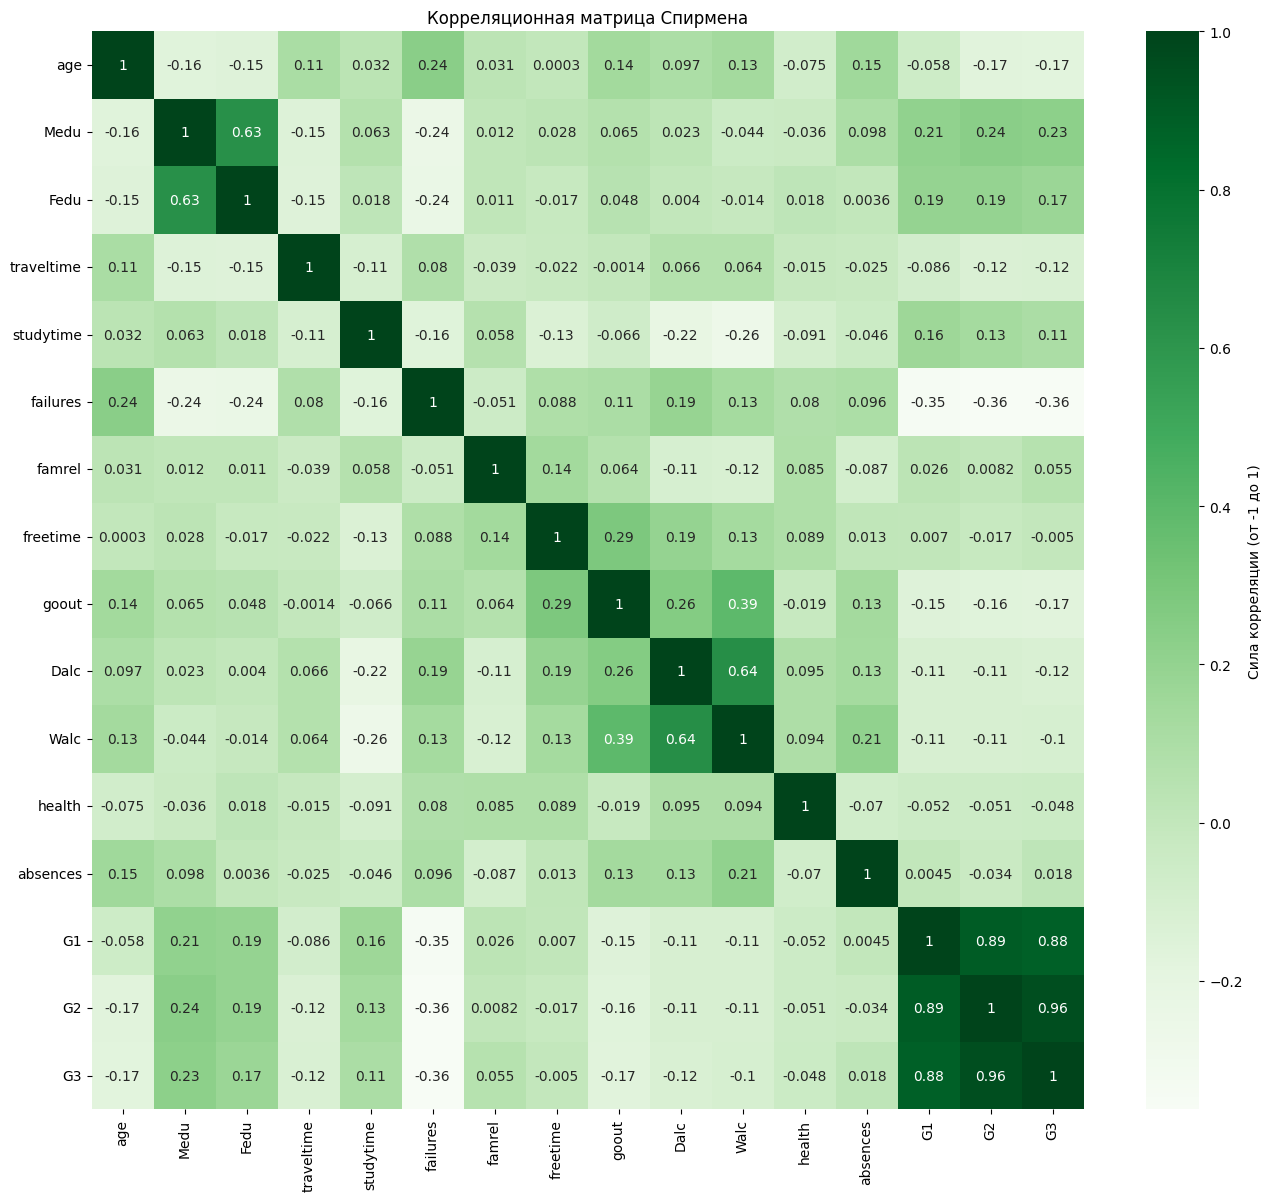

In [233]:
corr_matrix = df.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(16, 14))

# Добавляем параметр cbar_kws с заголовком 'label'
sns.heatmap(corr_matrix, annot=True, cmap='Greens',
            cbar_kws={'label': 'Сила корреляции (от -1 до 1)'})

plt.title("Корреляционная матрица Спирмена")
plt.show()


### Корреляции признаков с G3

Смотрим, какие числовые признаки сильнее всего связаны с итоговой оценкой G3.

In [234]:
corr_with_target = corr_matrix["G3"].drop("G3")
corr_with_target.sort_values(ascending=False).head(15).round(3)

G2            0.957
G1            0.878
Medu          0.225
Fedu          0.170
studytime     0.105
famrel        0.055
absences      0.018
freetime     -0.005
health       -0.048
Walc         -0.104
traveltime   -0.121
Dalc         -0.121
goout        -0.166
age          -0.173
failures     -0.361
Name: G3, dtype: float64

### Положительные связи с G3

Отдельно выводим признаки, которые растут вместе с G3.

In [235]:
corr_with_target_plus = corr_with_target[corr_with_target > 0].sort_values(ascending=False).round(3)
corr_with_target_plus.head(6)

G2           0.957
G1           0.878
Medu         0.225
Fedu         0.170
studytime    0.105
famrel       0.055
Name: G3, dtype: float64

### Отрицательные связи с G3

Отдельно выводим признаки, которые связаны со снижением G3.

In [236]:
corr_with_target_minus = corr_with_target[corr_with_target < 0].sort_values(ascending=True).round(3)
corr_with_target_minus.head(7)

failures     -0.361
age          -0.173
goout        -0.166
Dalc         -0.121
traveltime   -0.121
Walc         -0.104
health       -0.048
Name: G3, dtype: float64

### Распределение целевой переменной

Строим гистограмму G3, чтобы увидеть, какие итоговые оценки встречаются чаще всего.

Text(0, 0.5, 'Количество студентов')

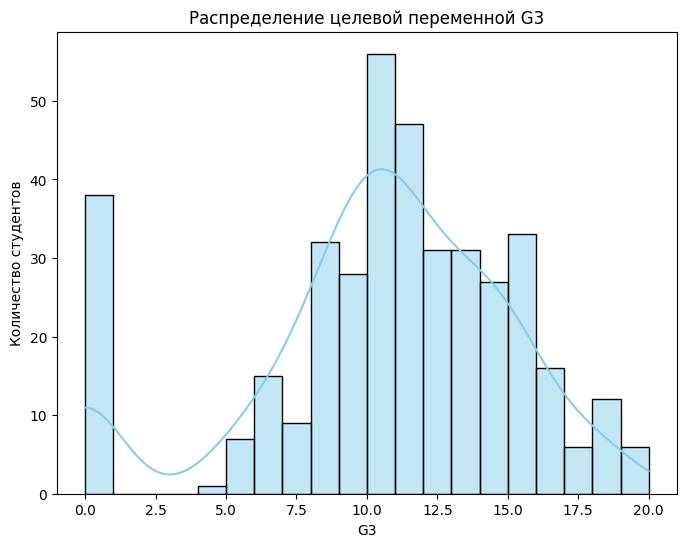

In [237]:
df_g3 = df[["G3"]]
plt.figure(figsize=(8, 6))
sns.histplot(df_g3["G3"], bins=20, kde=True, color="skyblue")
plt.title("Распределение целевой переменной G3")
plt.xlabel("G3")
plt.ylabel("Количество студентов")

### Статистика по G3

Смотрим минимум, максимум, среднее, медиану и квартили целевой переменной.

In [238]:
df["G3"].describe()

count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

### Средняя G3 по количеству прошлых неудач

Проверяем, как меняется средняя итоговая оценка при разном значении failures.

In [239]:
df.groupby("failures")["G3"].mean()

failures
0    11.253205
1     8.120000
2     6.235294
3     5.687500
Name: G3, dtype: float64

### Средняя G3 по времени учебы

Сравниваем среднюю итоговую оценку для разных значений studytime.

In [240]:
df.groupby("studytime")["G3"].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

### Средняя G3 по планам на высшее образование

Проверяем различие средней G3 между группами higher = yes и higher = no.

In [241]:
df.groupby("higher")["G3"].mean()

higher
no      6.800
yes    10.608
Name: G3, dtype: float64

## 2. Обучение и сравнение на двух датасетах

В этом разделе сравниваем простую baseline-модель и LinearRegression. Проверяем два сценария признаков: с промежуточными оценками G1/G2 и без них.

### 2.1 Основной датасет student_data.csv

Начинаем с маленького датасета, потому что на нем проще проверить логику обучения и интерпретировать результат.

### Импорт инструментов для обучения

Подключаем функции для train/test split, baseline-модель и метрики качества.

In [242]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Подготовка двух наборов признаков

Создаем два сценария: X_with_grades использует G1 и G2, а X_without_grades исключает их. Целевая переменная в обоих случаях - G3.

In [243]:
X_with_grades = df_encoding.drop(["G3"], axis=1)
X_without_grades = df_encoding.drop(["G1", "G2", "G3"], axis=1)
y = df_encoding["G3"]

### Train/test split для baseline с G1/G2

Делим данные на train и test для baseline-модели с промежуточными оценками.

In [244]:
X_train, X_test, y_train, y_test = train_test_split(
    X_with_grades,
    y,
    test_size=0.3,
    random_state=42)

### Dummy baseline с G1/G2

Обучаем простую baseline-модель, которая предсказывает среднее значение G3.

In [245]:
dummy_model_with_grades = DummyRegressor(strategy="mean")
dummy_model_with_grades.fit(X_train, y_train)

y_pred_dummy_with_grades = dummy_model_with_grades.predict(X_test)
print(f"Dummy model with grades")

Dummy model with grades


### Метрики Dummy baseline с G1/G2

Считаем MAE, RMSE и R2 для baseline-модели.

In [246]:
mae = mean_absolute_error(y_test, y_pred_dummy_with_grades)
rmse = mean_squared_error(y_test, y_pred_dummy_with_grades) ** 0.5
r2 = r2_score(y_test, y_pred_dummy_with_grades)

print(f"Dummy model with grades")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

Dummy model with grades
MAE: 3.691
RMSE: 4.691
R²: -0.001


### Train/test split для baseline без G1/G2

Делим данные на train и test для baseline-модели без промежуточных оценок.

In [247]:
X_train, X_test, y_train, y_test = train_test_split(
    X_without_grades,
    y,
    test_size=0.3,
    random_state=42)

### Dummy baseline без G1/G2

Повторяем baseline для второго сценария. Для DummyRegressor результат ожидаемо такой же, потому что он не использует признаки.

In [248]:
dummy_model_without_grades = DummyRegressor(strategy="mean")
dummy_model_without_grades.fit(X_train, y_train)

y_pred_dummy_without_grades = dummy_model_without_grades.predict(X_test)
print(f"Dummy model without grades")

Dummy model without grades


### Метрики Dummy baseline без G1/G2

Считаем MAE, RMSE и R2 для baseline-модели во втором сценарии.

In [249]:
mae = mean_absolute_error(y_test, y_pred_dummy_without_grades)
rmse = mean_squared_error(y_test, y_pred_dummy_without_grades) ** 0.5
r2 = r2_score(y_test, y_pred_dummy_without_grades)

print(f"Dummy model without grades")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

Dummy model without grades
MAE: 3.691
RMSE: 4.691
R²: -0.001


### Импорт cross-validation и LinearRegression

Подключаем cross-validation и простую линейную модель для сравнения с baseline.

In [250]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

### LinearRegression с G1/G2

Оцениваем линейную регрессию через 7-fold cross-validation по MAE.

In [251]:
model = LinearRegression()
linear_reg_mae_scores_with_grades = -cross_val_score(
    model,
    X_with_grades,
    y,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_with_grades.mean().round(3)

np.float64(1.371)

### LinearRegression без G1/G2

Повторяем cross-validation без промежуточных оценок, чтобы понять, насколько они важны для прогноза G3.

In [252]:
linear_reg_mae_scores_without_grades = -cross_val_score(
    model,
    X_without_grades,
    y,
    cv=7,
    scoring='neg_mean_absolute_error')

linear_reg_mae_scores_without_grades.mean().round(3)

np.float64(3.435)

### Визуальное сравнение MAE на основном датасете

Строим столбчатый график, чтобы сравнить baseline и LinearRegression в двух сценариях признаков. Чем ниже MAE, тем лучше.

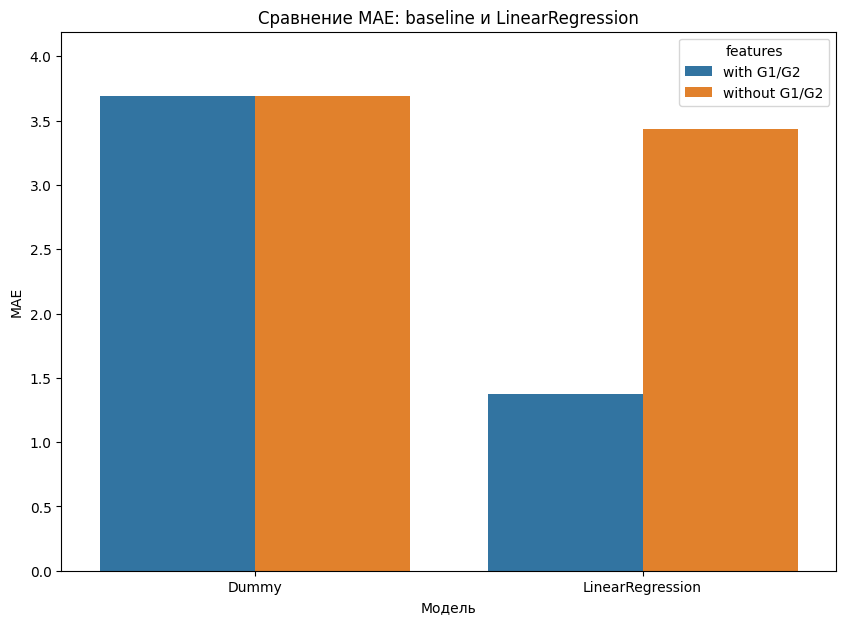

In [253]:
results = pd.DataFrame({
    "model": [
        "Dummy",
        "Dummy",
        "LinearRegression",
        "LinearRegression",
    ],
    "features": [
        "with G1/G2",
        "without G1/G2",
        "with G1/G2",
        "without G1/G2",
    ],
    "MAE": [
        3.691,
        3.691,
        linear_reg_mae_scores_with_grades.mean(),
        linear_reg_mae_scores_without_grades.mean(),
    ],
})

plt.figure(figsize=(10, 7))

sns.barplot(
    data=results,
    x="model",
    y="MAE",
    hue="features"
)

plt.title("Сравнение MAE: baseline и LinearRegression")
plt.xlabel("Модель")
plt.ylabel("MAE")
plt.ylim(0, results["MAE"].max() + 0.5)
plt.show()

### 2.2 Расширенный датасет student_data_500k.csv

Переходим к большому датасету. Не повторяем полный EDA, потому что структура почти такая же, а смотрим только ключевые проверки: загрузку, распределение G3, описательную статистику и сравнение моделей.

In [254]:
DATA_PATH = Path("../data/raw/student_data_500k.csv")
df_500 = pd.read_csv(DATA_PATH)
df_500.head()

,record_id,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,1,GP,F,15,U,GT3,T,2,3,other,...,2,5,1,1,1,5,0,8,7,6
1,2,GP,F,18,U,GT3,T,3,4,services,...,4,4,3,1,1,3,6,13,13,11
2,3,GP,M,18,U,GT3,T,2,1,other,...,5,2,4,1,2,4,8,14,13,12
3,4,GP,F,16,U,GT3,T,1,3,at_home,...,4,3,5,1,1,3,1,9,7,3
4,5,GP,M,16,U,GT3,T,1,0,other,...,4,3,2,1,1,3,4,13,14,12


### One-hot encoding для 500k и удаление record_id

Кодируем категориальные признаки и удаляем record_id, потому что это технический номер строки, а не характеристика студента.

In [255]:
df_500_encoding = pd.get_dummies(df_500, drop_first=True, dtype=int).drop(["record_id"], axis=1)

### Распределение G3 на 500k

Строим распределение целевой переменной на расширенном датасете.

Text(0, 0.5, 'Количество студентов')

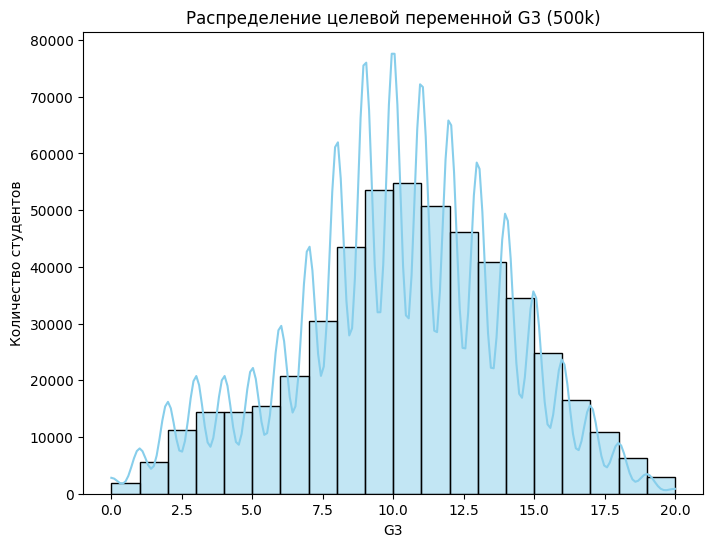

In [256]:
df_500_g3 = df_500[["G3"]]
plt.figure(figsize=(8, 6))
sns.histplot(df_500_g3["G3"], bins=20, kde=True, color="skyblue")
plt.title("Распределение целевой переменной G3 (500k)")
plt.xlabel("G3")
plt.ylabel("Количество студентов")

### Статистика G3 на 500k

Смотрим count, mean, std, min, max и квартили целевой переменной.

In [257]:
df_500_encoding["G3"].describe()

count    500000.000000
mean         10.082362
std           3.838412
min           0.000000
25%           8.000000
50%          10.000000
75%          13.000000
max          20.000000
Name: G3, dtype: float64

### Подготовка признаков для 500k

Создаем два сценария признаков: с G1/G2 и без G1/G2. Целевая переменная сохраняется отдельно как y_500.

In [258]:
X_500_with_grades = df_500_encoding.drop(["G3"], axis=1)
X_500_without_grades = df_500_encoding.drop(["G1", "G2", "G3"], axis=1)
y_500 = df_500_encoding["G3"]

### Dummy baseline на 500k

Считаем baseline через cross-validation. Одного baseline достаточно, потому что DummyRegressor не использует признаки.

In [259]:
DummyRegressor_mae_scores_500_grades = -cross_val_score(
    DummyRegressor(),
    X_500_with_grades,
    y_500,
    cv=7,
    scoring='neg_mean_absolute_error')

DummyRegressor_mae_scores_500_grades.mean().round(3)

np.float64(3.046)

In [260]:
from sklearn.model_selection import cross_validate

### LinearRegression на 500k с G1/G2

Оцениваем линейную регрессию на расширенном датасете с промежуточными оценками.

In [261]:
model = LinearRegression()
scoring = {
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error',
    'R2': 'r2'
}

linear_reg_scores_500_with_grades = cross_validate(
    model,
    X_500_with_grades,
    y_500,
    cv=7,
    scoring=scoring)

linear_metrics_500_with_grades = pd.DataFrame({
    'features': ['with G1/G2'],
    'MAE': [-linear_reg_scores_500_with_grades['test_mae'].mean()],
    'MSE': [-linear_reg_scores_500_with_grades['test_mse'].mean()],
    'R2': [linear_reg_scores_500_with_grades['test_R2'].mean()]
})

linear_metrics_500_with_grades.round(3)

,features,MAE,MSE,R2
0,with G1/G2,1.165,2.242,0.848


### LinearRegression на 500k без G1/G2

Оцениваем линейную регрессию без промежуточных оценок, чтобы сравнить силу остальных признаков.

In [262]:
linear_reg_scores_500_without_grades = cross_validate(
    model,
    X_500_without_grades,
    y_500,
    cv=7,
    scoring=scoring)

linear_metrics_500_without_grades = pd.DataFrame({
    'features': ['without G1/G2'],
    'MAE': [-linear_reg_scores_500_without_grades['test_mae'].mean()],
    'MSE': [-linear_reg_scores_500_without_grades['test_mse'].mean()],
    'R2': [linear_reg_scores_500_without_grades['test_R2'].mean()]
})
linear_metrics_500_without_grades.round(3)

,features,MAE,MSE,R2
0,without G1/G2,2.619,10.759,0.27


### Визуальное сравнение MAE на 500k

Строим график MAE для baseline и LinearRegression на расширенном датасете.

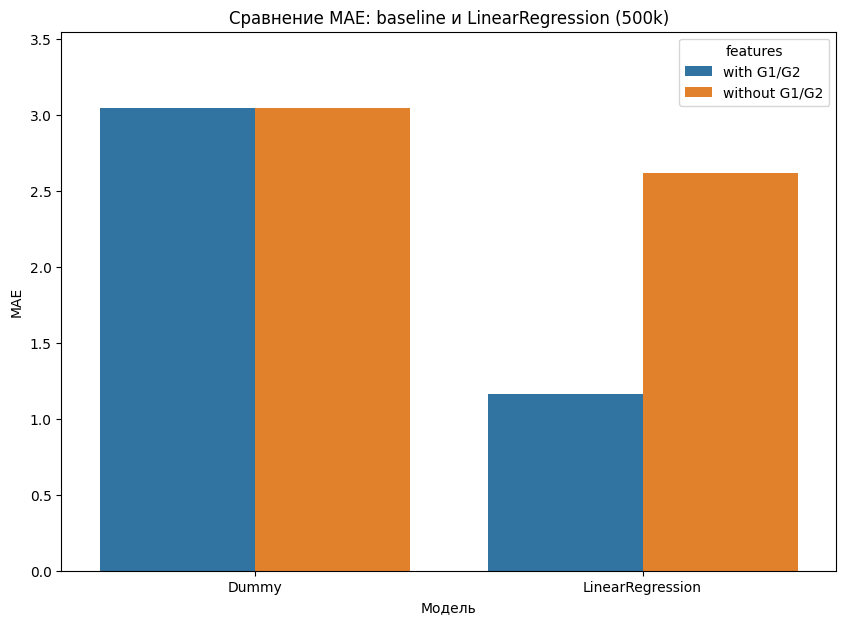

In [263]:
results = pd.DataFrame({
    "model": [
        "Dummy",
        "Dummy",
        "LinearRegression",
        "LinearRegression",
    ],
    "features": [
        "with G1/G2",
        "without G1/G2",
        "with G1/G2",
        "without G1/G2",
    ],
    "MAE": [
        3.046,
        3.046,
        linear_metrics_500_with_grades['MAE'].mean(),
        linear_metrics_500_without_grades['MAE'].mean(),
    ],
})

plt.figure(figsize=(10, 7))

sns.barplot(
    data=results,
    x="model",
    y="MAE",
    hue="features"
)

plt.title("Сравнение MAE: baseline и LinearRegression (500k)")
plt.xlabel("Модель")
plt.ylabel("MAE")
plt.ylim(0, results["MAE"].max() + 0.5)
plt.show()

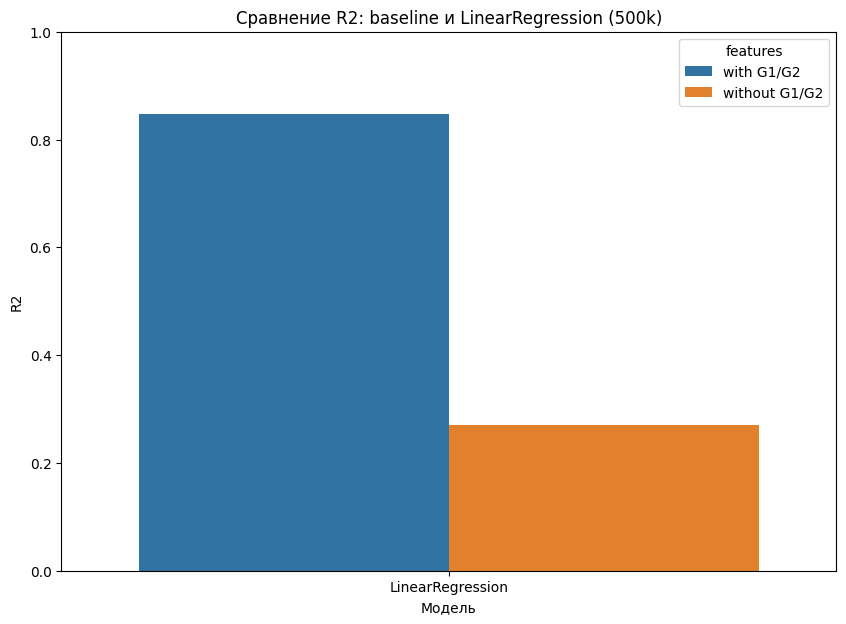

In [264]:
results = pd.DataFrame({
    "model": [
        "LinearRegression",
        "LinearRegression",
    ],
    "features": [
        "with G1/G2",
        "without G1/G2",
    ],
    "R2": [
        linear_metrics_500_with_grades['R2'].mean(),
        linear_metrics_500_without_grades['R2'].mean(),
    ],
})

plt.figure(figsize=(10, 7))

sns.barplot(
    data=results,
    x="model",
    y="R2",
    hue="features"
)

plt.title("Сравнение R2: baseline и LinearRegression (500k)")
plt.xlabel("Модель")
plt.ylabel("R2")
plt.ylim(0, 1)
plt.show()

In [265]:
from sklearn.model_selection import train_test_split

train_index, test_index = train_test_split(
    df_500_encoding.index,
    test_size=0.2,
    random_state=42)

In [266]:
X_train_with = X_500_with_grades.loc[train_index]
X_test_with = X_500_with_grades.loc[test_index]

X_train_without = X_500_without_grades.loc[train_index]
X_test_without = X_500_without_grades.loc[test_index]

y_train = y_500.loc[train_index]
y_test = y_500.loc[test_index]

In [267]:
print(X_train_with.shape)
print(X_test_with.shape)
print(X_train_without.shape)
print(X_test_without.shape)
print(y_train.shape)
print(y_test.shape)

(400000, 41)
(100000, 41)
(400000, 39)
(100000, 39)
(400000,)
(100000,)


In [268]:
from sklearn.ensemble import HistGradientBoostingRegressor

boosting_model_with_grades = HistGradientBoostingRegressor(
    learning_rate=0.005,
    max_iter=50000,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=30,
    random_state=42,
)

In [269]:
boosting_model_with_grades.fit(X_train_with, y_train)
y_pred_with = boosting_model_with_grades.predict(X_test_with)
mae_with = mean_absolute_error(y_test, y_pred_with)
mse_with = mean_squared_error(y_test, y_pred_with)
rmse_with = mse_with ** 0.5
r2_with = r2_score(y_test, y_pred_with)

In [270]:
print(f"MAE:  {mae_with:.3f}")
print(f"MSE:  {mse_with:.3f}")
print(f"RMSE: {rmse_with:.3f}")
print(f"R2:   {r2_with:.3f}")

MAE:  0.842
MSE:  1.111
RMSE: 1.054
R2:   0.925


In [271]:
boosting_model_without_grades = HistGradientBoostingRegressor(
    learning_rate=0.005,
    max_iter=50000,
    max_leaf_nodes=31,
    min_samples_leaf=50,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=30,
    random_state=42,
)

In [272]:
boosting_model_without_grades.fit(X_train_without, y_train)
y_pred_without = boosting_model_without_grades.predict(X_test_without)
mae_without = mean_absolute_error(y_test, y_pred_without)
mse_without = mean_squared_error(y_test, y_pred_without)
rmse_without = mse_without ** 0.5
r2_without = r2_score(y_test, y_pred_without)

In [273]:
print("Without G1/G2:")
print(f"MAE:  {mae_without:.3f}")
print(f"MSE:  {mse_without:.3f}")
print(f"RMSE: {rmse_without:.3f}")
print(f"R2:   {r2_without:.3f}")

Without G1/G2:
MAE:  0.893
MSE:  1.250
RMSE: 1.118
R2:   0.915


In [274]:
print(boosting_model_with_grades.n_iter_)
print(boosting_model_without_grades.n_iter_)

18665
44025


## 3. Диагностика градиентного бустинга

В этом разделе отделяем validation от финального test, строим кривые MAE и R2 по контрольным итерациям и визуализируем ошибки модели. Test не используется для выбора количества итераций.

### Отдельная validation-выборка

Берем 10% от исходной train-части для наблюдения за обучением. Финальная test-часть остается нетронутой.

In [275]:
train_inner_index, val_index = train_test_split(
    train_index,
    test_size=0.1,
    random_state=42,
)

X_train_curve_with = X_500_with_grades.loc[train_inner_index]
X_val_curve_with = X_500_with_grades.loc[val_index]

X_train_curve_without = X_500_without_grades.loc[train_inner_index]
X_val_curve_without = X_500_without_grades.loc[val_index]

y_train_curve = y_500.loc[train_inner_index]
y_val_curve = y_500.loc[val_index]

print(X_train_curve_with.shape, X_val_curve_with.shape)
print(y_train_curve.shape, y_val_curve.shape)

(360000, 41) (40000, 41)
(360000,) (40000,)


### Контрольные точки итераций

В начале метрики проверяются чаще, затем реже. Это дает информативную кривую без 500 дорогих проверок на validation.

In [276]:
iteration_checkpoints = (
    list(range(100, 1001, 100))
    + list(range(1500, 10001, 500))
    + list(range(15000, 50001, 5000))
)

iteration_checkpoints

[100,
 200,
 300,
 400,
 500,
 600,
 700,
 800,
 900,
 1000,
 1500,
 2000,
 2500,
 3000,
 3500,
 4000,
 4500,
 5000,
 5500,
 6000,
 6500,
 7000,
 7500,
 8000,
 8500,
 9000,
 9500,
 10000,
 15000,
 20000,
 25000,
 30000,
 35000,
 40000,
 45000,
 50000]

### Функция сбора MAE и R2

`warm_start=True` продолжает обучение существующей модели до следующей контрольной точки. Для этой диагностической модели early stopping выключен, потому что остановку анализируем вручную по validation-кривой.

Запуск до 50 000 итераций на 500k строках может занять очень много времени. Для первого теста можно временно заменить последнюю точку на 5 000 или 10 000.

In [277]:
def collect_boosting_history(X_train, y_train, X_val, y_val, checkpoints):
    model = HistGradientBoostingRegressor(
        learning_rate=0.005,
        max_iter=checkpoints[0],
        max_leaf_nodes=31,
        min_samples_leaf=50,
        l2_regularization=1.0,
        early_stopping=False,
        warm_start=True,
        random_state=42,
    )

    history = []

    for iteration in checkpoints:
        model.set_params(max_iter=iteration)
        model.fit(X_train, y_train)

        y_val_pred = model.predict(X_val)
        val_mae = mean_absolute_error(y_val, y_val_pred)
        val_r2 = r2_score(y_val, y_val_pred)

        history.append({
            "iteration": iteration,
            "MAE": val_mae,
            "R2": val_r2,
        })

        print(
            f"iteration={iteration:>5} | "
            f"MAE={val_mae:.4f} | R2={val_r2:.4f}"
        )

    return model, pd.DataFrame(history)

### Кривая обучения с G1/G2

Этот блок может быть долгим. Сначала рекомендуется выполнить его с контрольными точками только до 5 000 или 10 000.

In [278]:
curve_model_with, history_with = collect_boosting_history(
    X_train_curve_with,
    y_train_curve,
    X_val_curve_with,
    y_val_curve,
    iteration_checkpoints,
)

history_with.tail()

iteration=  100 | MAE=2.0268 | R2=0.5523
iteration=  200 | MAE=1.4836 | R2=0.7600
iteration=  300 | MAE=1.2111 | R2=0.8405
iteration=  400 | MAE=1.0782 | R2=0.8736
iteration=  500 | MAE=1.0118 | R2=0.8885
iteration=  600 | MAE=0.9763 | R2=0.8962
iteration=  700 | MAE=0.9556 | R2=0.9006
iteration=  800 | MAE=0.9415 | R2=0.9036
iteration=  900 | MAE=0.9320 | R2=0.9057
iteration= 1000 | MAE=0.9241 | R2=0.9073
iteration= 1500 | MAE=0.9019 | R2=0.9119
iteration= 2000 | MAE=0.8889 | R2=0.9145
iteration= 2500 | MAE=0.8800 | R2=0.9163
iteration= 3000 | MAE=0.8736 | R2=0.9176
iteration= 3500 | MAE=0.8688 | R2=0.9186
iteration= 4000 | MAE=0.8646 | R2=0.9195
iteration= 4500 | MAE=0.8613 | R2=0.9202
iteration= 5000 | MAE=0.8588 | R2=0.9206
iteration= 5500 | MAE=0.8568 | R2=0.9211
iteration= 6000 | MAE=0.8552 | R2=0.9214
iteration= 6500 | MAE=0.8540 | R2=0.9216
iteration= 7000 | MAE=0.8528 | R2=0.9219
iteration= 7500 | MAE=0.8518 | R2=0.9221
iteration= 8000 | MAE=0.8509 | R2=0.9222
iteration= 8500 

,iteration,MAE,R2
31,30000,0.842700,0.923968
32,35000,0.842687,0.923966
33,40000,0.842670,0.923970
34,45000,0.842941,0.923925
35,50000,0.843080,0.923901


### Кривая обучения без G1/G2

Второй сценарий особенно важен: здесь проверяем, может ли нелинейная модель компенсировать отсутствие промежуточных оценок.

In [279]:
curve_model_without, history_without = collect_boosting_history(
    X_train_curve_without,
    y_train_curve,
    X_val_curve_without,
    y_val_curve,
    iteration_checkpoints,
)

history_without.tail()

iteration=  100 | MAE=2.5659 | R2=0.3043
iteration=  200 | MAE=2.2233 | R2=0.4798
iteration=  300 | MAE=1.9640 | R2=0.5926
iteration=  400 | MAE=1.7750 | R2=0.6645
iteration=  500 | MAE=1.6347 | R2=0.7118
iteration=  600 | MAE=1.5254 | R2=0.7469
iteration=  700 | MAE=1.4349 | R2=0.7736
iteration=  800 | MAE=1.3648 | R2=0.7934
iteration=  900 | MAE=1.3063 | R2=0.8097
iteration= 1000 | MAE=1.2600 | R2=0.8224
iteration= 1500 | MAE=1.1058 | R2=0.8626
iteration= 2000 | MAE=1.0396 | R2=0.8793
iteration= 2500 | MAE=1.0035 | R2=0.8882
iteration= 3000 | MAE=0.9848 | R2=0.8929
iteration= 3500 | MAE=0.9699 | R2=0.8965
iteration= 4000 | MAE=0.9603 | R2=0.8988
iteration= 4500 | MAE=0.9527 | R2=0.9006
iteration= 5000 | MAE=0.9465 | R2=0.9021
iteration= 5500 | MAE=0.9410 | R2=0.9035
iteration= 6000 | MAE=0.9370 | R2=0.9045
iteration= 6500 | MAE=0.9338 | R2=0.9053
iteration= 7000 | MAE=0.9309 | R2=0.9059
iteration= 7500 | MAE=0.9285 | R2=0.9065
iteration= 8000 | MAE=0.9267 | R2=0.9070
iteration= 8500 

,iteration,MAE,R2
31,30000,0.896737,0.913933
32,35000,0.894692,0.914405
33,40000,0.893668,0.914663
34,45000,0.892769,0.914873
35,50000,0.891953,0.915059


### Графики кривых MAE и R2

MAE должна уменьшаться, а R2 увеличиваться. Плато показывает, что дополнительные итерации почти перестали улучшать validation-качество.

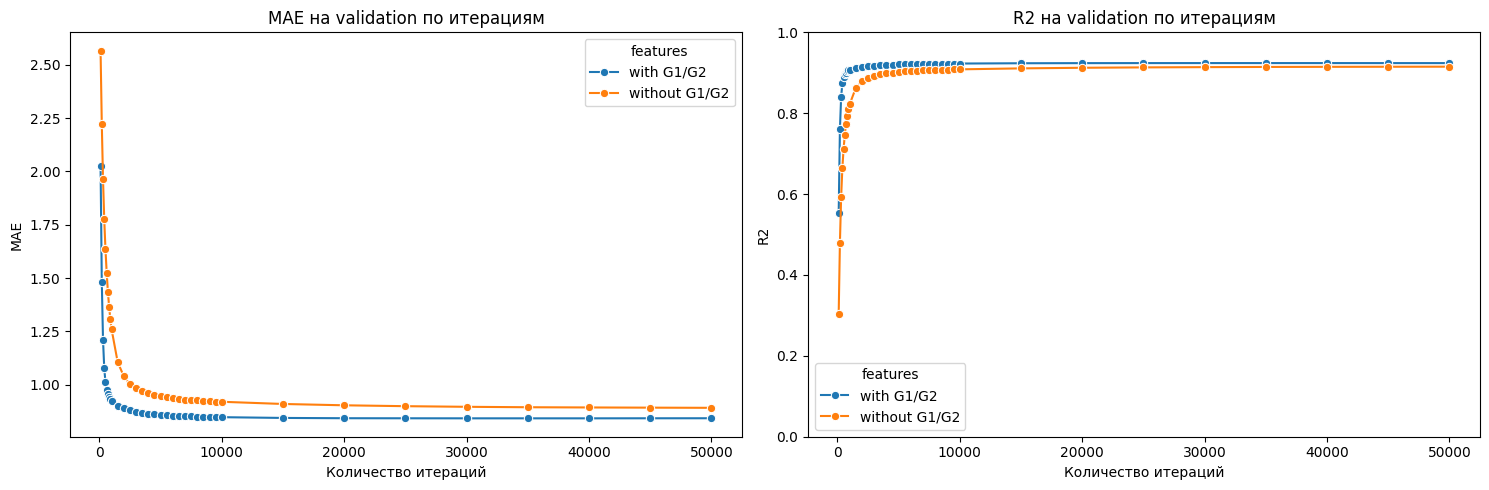

In [280]:
history_with_plot = history_with.assign(features="with G1/G2")
history_without_plot = history_without.assign(features="without G1/G2")
history_all = pd.concat(
    [history_with_plot, history_without_plot],
    ignore_index=True,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=history_all,
    x="iteration",
    y="MAE",
    hue="features",
    marker="o",
    ax=axes[0],
)
axes[0].set_title("MAE на validation по итерациям")
axes[0].set_xlabel("Количество итераций")
axes[0].set_ylabel("MAE")

sns.lineplot(
    data=history_all,
    x="iteration",
    y="R2",
    hue="features",
    marker="o",
    ax=axes[1],
)
axes[1].set_title("R2 на validation по итерациям")
axes[1].set_xlabel("Количество итераций")
axes[1].set_ylabel("R2")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Факт против прогноза и остатки

Левая диаграмма показывает близость прогнозов к идеальной диагонали. Правая показывает остатки: желательно, чтобы они располагались вокруг нуля без явного рисунка.

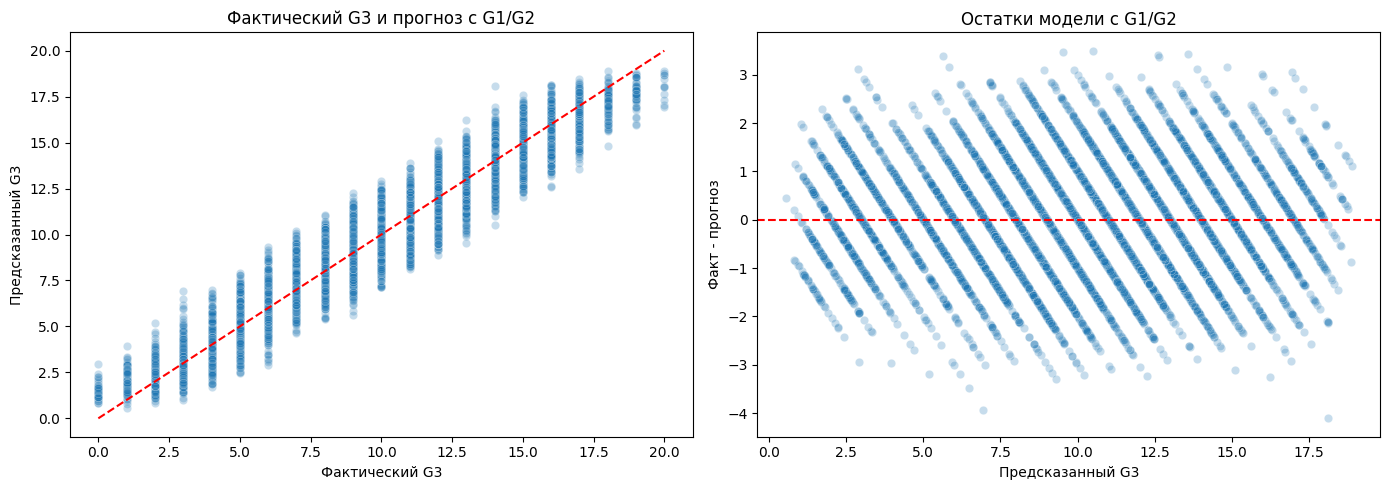

In [281]:
residuals_with = y_test - y_pred_with

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample_plot = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred_with,
}).sample(n=10000, random_state=42)

sns.scatterplot(
    data=sample_plot,
    x="actual",
    y="predicted",
    alpha=0.25,
    ax=axes[0],
)
axes[0].plot([0, 20], [0, 20], color="red", linestyle="--")
axes[0].set_title("Фактический G3 и прогноз с G1/G2")
axes[0].set_xlabel("Фактический G3")
axes[0].set_ylabel("Предсказанный G3")

residual_plot = pd.DataFrame({
    "predicted": y_pred_with,
    "residual": residuals_with,
}).sample(n=10000, random_state=42)

sns.scatterplot(
    data=residual_plot,
    x="predicted",
    y="residual",
    alpha=0.25,
    ax=axes[1],
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Остатки модели с G1/G2")
axes[1].set_xlabel("Предсказанный G3")
axes[1].set_ylabel("Факт - прогноз")

plt.tight_layout()
plt.show()

### Permutation importance

Histogram boosting не предоставляет обычный `feature_importances_`. Поэтому используем permutation importance: перемешиваем один признак и измеряем, насколько ухудшилась MAE. Для контроля времени берем 10 000 test-строк и 3 повтора.

In [282]:
from sklearn.inspection import permutation_importance

importance_sample = X_test_with.sample(n=10000, random_state=42)
y_importance_sample = y_test.loc[importance_sample.index]

permutation_result = permutation_importance(
    boosting_model_with_grades,
    importance_sample,
    y_importance_sample,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1,
)

feature_importance = pd.DataFrame({
    "feature": importance_sample.columns,
    "importance": permutation_result.importances_mean,
}).sort_values("importance", ascending=False)

feature_importance.head(15)

,feature,importance
14,G2,1.529160
13,G1,0.724547
12,absences,0.071558
0,age,0.045573
40,romantic_yes,0.036689
36,activities_yes,0.026985
35,paid_yes,0.025059
5,failures,0.024411
33,schoolsup_yes,0.023787
11,health,0.021301


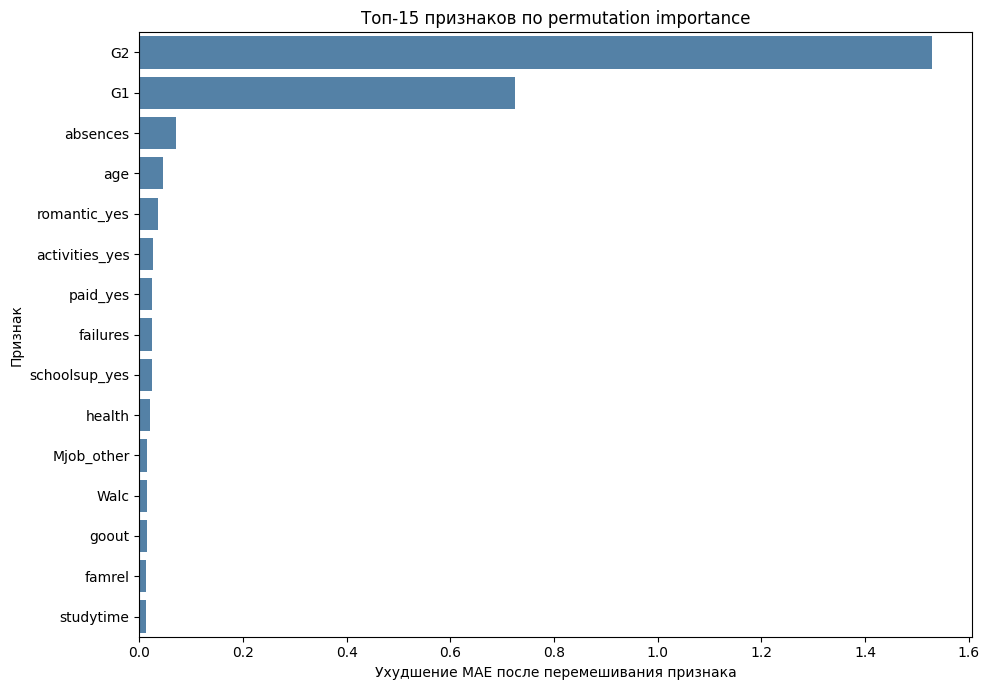

In [283]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="importance",
    y="feature",
    color="steelblue",
)

plt.title("Топ-15 признаков по permutation importance")
plt.xlabel("Ухудшение MAE после перемешивания признака")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### Визуализация отдельного дерева

Деревья `HistGradientBoostingRegressor` хранятся во внутреннем формате и напрямую через `plot_tree` не визуализируются. Для учебной демонстрации отдельного дерева позже можно обучить небольшой классический `GradientBoostingRegressor` на подвыборке. Он не заменяет основную histogram-модель.